In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import matplotlib.pyplot as plt
import tensorflow as tf
import pandas as pd
import numpy as np

import warnings
warnings.filterwarnings('ignore')

from tensorflow import keras
from keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Activation, Dropout, Flatten, Dense
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.utils import image_dataset_from_directory
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img
from tensorflow.keras.preprocessing import image_dataset_from_directory

import os
import matplotlib.image as mpimg

In [ ]:
from zipfile import ZipFile

data_path = '/content/drive/MyDrive/khdl2/deep/CNN/archive.zip'

with ZipFile(data_path, 'r') as zip:
    zip.extractall()
    print('The data set has been extracted.')

The data set has been extracted.


In [ ]:
#from zipfile import ZipFile
#data_path = 'archive.zip'
#with ZipFile(data_path, 'r') as zip:
  #  zip.extractall()
   # print('The data set has been extracted.')

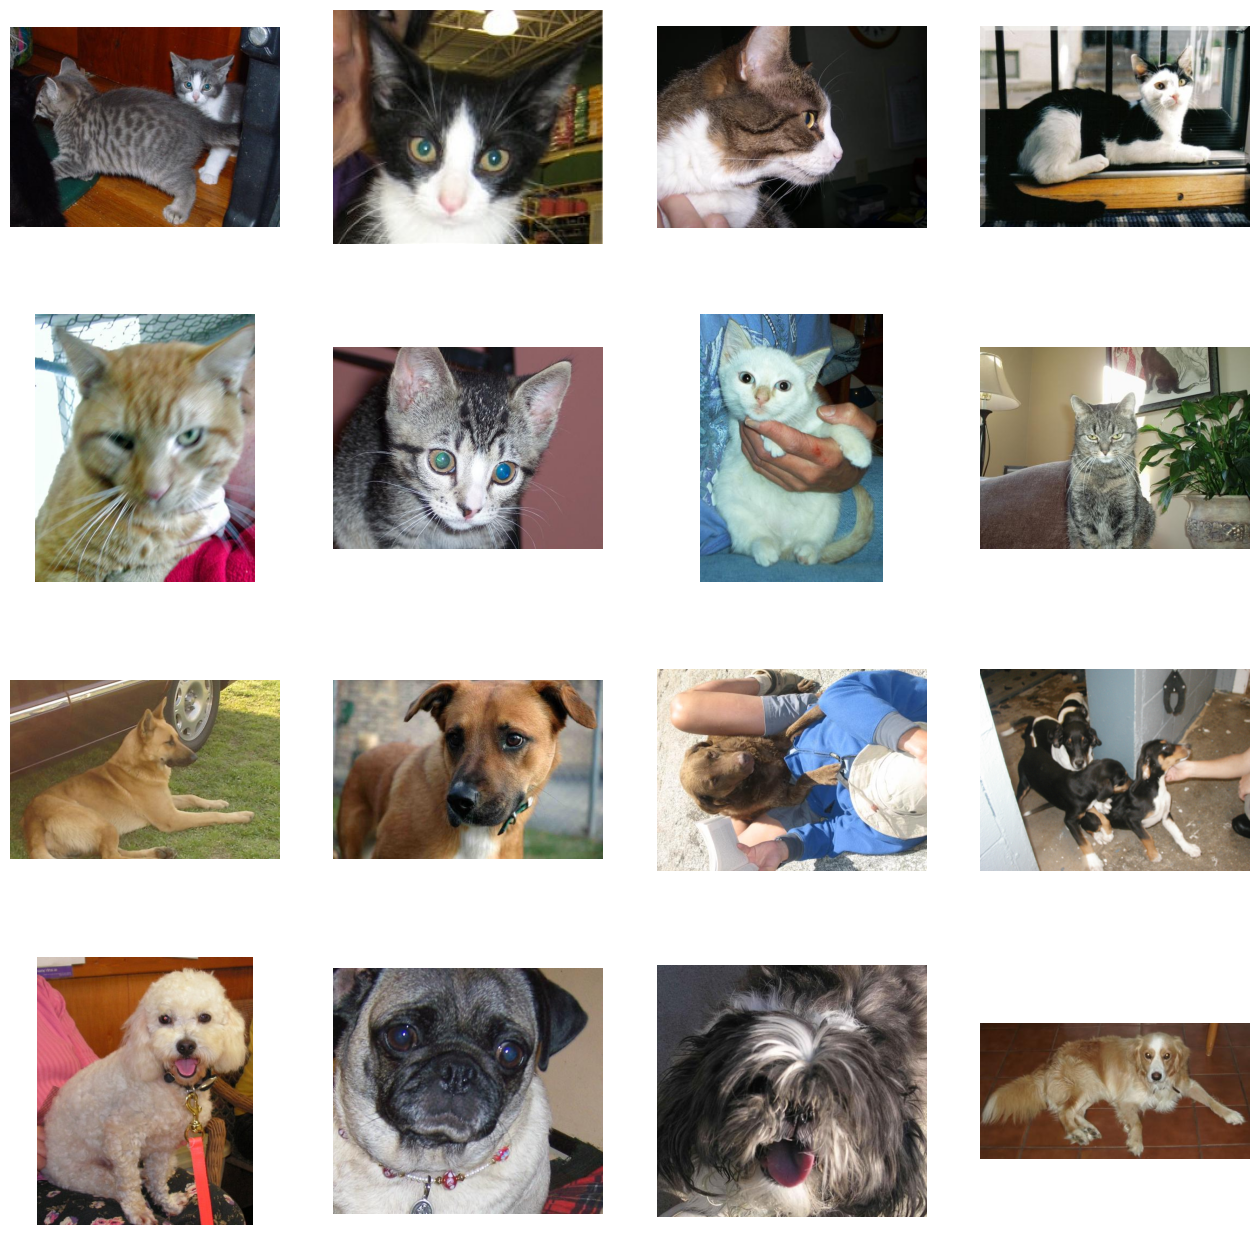

In [ ]:
fig = plt.gcf()
fig.set_size_inches(16, 16)

cat_dir = os.path.join('PetImages/Cat')
dog_dir = os.path.join('PetImages/Dog')
cat_names = os.listdir(cat_dir)
dog_names = os.listdir(dog_dir)

pic_index = 210

cat_images = [os.path.join(cat_dir, fname)
              for fname in cat_names[pic_index-8:pic_index]]
dog_images = [os.path.join(dog_dir, fname)
              for fname in dog_names[pic_index-8:pic_index]]

for i, img_path in enumerate(cat_images + dog_images):
    sp = plt.subplot(4, 4, i+1)
    sp.axis('Off')

    img = mpimg.imread(img_path)
    plt.imshow(img)

plt.show()

In [ ]:
base_dir = 'PetImages'

train_datagen = image_dataset_from_directory(base_dir,
                                                  image_size=(200,200),
                                                  subset='training',
                                                  seed = 1,
                                                 validation_split=0.1,
                                                  batch_size= 32)
test_datagen = image_dataset_from_directory(base_dir,
                                                  image_size=(200,200),
                                                  subset='validation',
                                                  seed = 1,
                                                 validation_split=0.1,
                                                  batch_size= 32)

Found 25000 files belonging to 2 classes.
Using 22500 files for training.
Found 25000 files belonging to 2 classes.
Using 2500 files for validation.


In [ ]:
model = tf.keras.models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(200, 200, 3)),
    layers.MaxPooling2D(2, 2),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),

    layers.Flatten(),
    layers.Dense(512, activation='relu'),
    layers.BatchNormalization(),
    layers.Dense(512, activation='relu'),
    layers.Dropout(0.1),
    layers.BatchNormalization(),
    layers.Dense(512, activation='relu'),
    layers.Dropout(0.2),
    layers.BatchNormalization(),
    layers.Dense(1, activation='sigmoid')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 198, 198, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 99, 99, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 97, 97, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 48, 48, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 46, 46, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 23, 23, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 21, 21, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 10, 10, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     3,277,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,902,529 (14.89 MB)

 Trainable params: 3,899,457 (14.88 MB)

 Non-trainable params: 3,072 (12.00 KB)

In [ ]:
import os

# Hàm tìm và xóa các ảnh lỗi (ảnh rỗng hoặc không phải định dạng RGB hợp lệ)
for folder in ['Cat', 'Dog']:
    folder_path = os.path.join('PetImages', folder)
    for filename in os.listdir(folder_path):
        file_path = os.path.join(folder_path, filename)
        try:
            with open(file_path, 'rb') as f:
                # Kiểm tra xem ảnh có chứa header hợp lệ không
                is_jfif = b'JFIF' in f.peek(10)
            if not is_jfif:
                # Nếu không phải ảnh JPEG chuẩn, tiến hành xóa
                os.remove(file_path)
        except Exception:
            # Nếu có lỗi khi đọc file, cũng tiến hành xóa
            if os.path.exists(file_path):
                os.remove(file_path)

print("Đã hoàn thành việc dọn dẹp các ảnh lỗi.")

# Khởi tạo lại dataset sau khi đã dọn dẹp để cập nhật danh sách file
train_datagen = image_dataset_from_directory(base_dir,
                                                  image_size=(200,200),
                                                  subset='training',
                                                  seed = 1,
                                                 validation_split=0.1,
                                                  batch_size= 32)
test_datagen = image_dataset_from_directory(base_dir,
                                                  image_size=(200,200),
                                                  subset='validation',
                                                  seed = 1,
                                                 validation_split=0.1,
                                                  batch_size= 32)

# Tiến hành compile và huấn luyện mô hình
model.compile(
    loss='binary_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

history = model.fit(train_datagen,
          epochs=10,
          validation_data=test_datagen)

Đã hoàn thành việc dọn dẹp các ảnh lỗi.
Found 23410 files belonging to 2 classes.
Using 21069 files for training.
Found 23410 files belonging to 2 classes.
Using 2341 files for validation.
Epoch 1/10
659/659 ━━━━━━━━━━━━━━━━━━━━ 1927s 3s/step - accuracy: 0.5988 - loss: 0.7052 - val_accuracy: 0.5463 - val_loss: 1.4447
Epoch 2/10
659/659 ━━━━━━━━━━━━━━━━━━━━ 1924s 3s/step - accuracy: 0.7016 - loss: 0.5746 - val_accuracy: 0.6984 - val_loss: 0.7220
Epoch 3/10
659/659 ━━━━━━━━━━━━━━━━━━━━ 1919s 3s/step - accuracy: 0.7672 - loss: 0.4886 - val_accuracy: 0.6954 - val_loss: 0.5533
Epoch 4/10
659/659 ━━━━━━━━━━━━━━━━━━━━ 1899s 3s/step - accuracy: 0.8041 - loss: 0.4266 - val_accuracy: 0.7950 - val_loss: 0.4425
Epoch 5/10
659/659 ━━━━━━━━━━━━━━━━━━━━ 1868s 3s/step - accuracy: 0.8287 - loss: 0.3822 - val_accuracy: 0.4998 - val_loss: 2.0819
Epoch 6/10
659/659 ━━━━━━━━━━━━━━━━━━━━ 1842s 3s/step - accuracy: 0.6994 - loss: 0.5672 - val_accuracy: 0.5613 - val_loss: 0.9807
Epoch 7/10
659/659 ━━━━━━━━━━━━

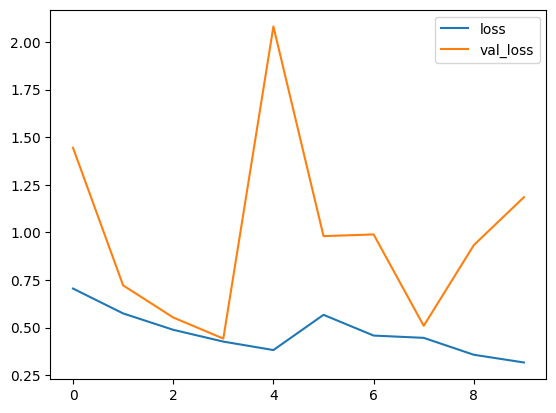

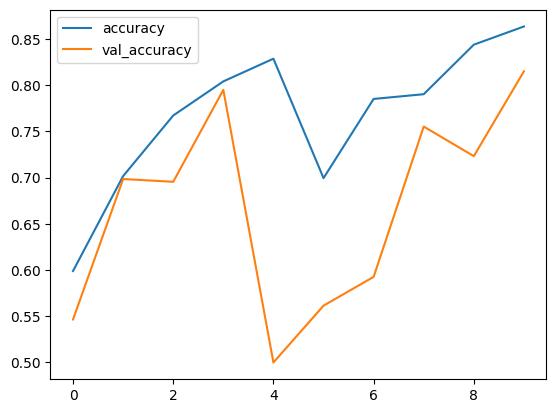

In [ ]:
history_df = pd.DataFrame(history.history)
history_df.loc[:, ['loss', 'val_loss']].plot()
history_df.loc[:, ['accuracy', 'val_accuracy']].plot()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 288ms/step
Cat
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
Dog


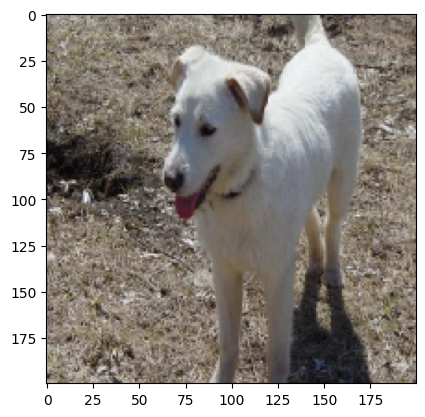

In [ ]:
from tensorflow.keras.preprocessing import image

def predict_image(image_path):
    img = image.load_img(image_path, target_size=(200, 200))
    plt.imshow(img)
    img = image.img_to_array(img)
    img = np.expand_dims(img, axis=0)

    result = model.predict(img)
    print("Dog" if result >= 0.5 else "Cat")

# Sử dụng các tệp ảnh hợp lệ trong thư mục PetImages
cat_files = os.listdir('PetImages/Cat')
dog_files = os.listdir('PetImages/Dog')

predict_image(os.path.join('PetImages/Cat', cat_files[0]))
predict_image(os.path.join('PetImages/Dog', dog_files[0]))

In [5]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import io
from PIL import Image
import numpy as np
from tensorflow.keras.preprocessing import image

# Tạo các widget cho giao diện
uploader = widgets.FileUpload(
    accept='image/*',  # Chỉ chấp nhận file ảnh
    multiple=False,    # Chỉ cho phép chọn 1 ảnh
    description='Tải ảnh lên'
)

output_image = widgets.Output()
output_prediction = widgets.Output()

def on_image_upload(change):
    with output_image:
        clear_output()
        # Lấy file ảnh vừa tải lên
        uploaded_file = list(uploader.value.values())[0]
        img_content = uploaded_file['content']

        # Hiển thị ảnh vừa tải lên
        img = Image.open(io.BytesIO(img_content))
        img_resized_display = img.resize((200, 200))
        display(img_resized_display)

    with output_prediction:
        clear_output()
        print("Đang xử lý và dự đoán...")
        try:
            # Tiền xử lý ảnh để đưa vào model
            img_processed = img.resize((200, 200))
            img_array = image.img_to_array(img_processed)
            img_array = np.expand_dims(img_array, axis=0)

            # Dự đoán sử dụng model đã huấn luyện
            result = model.predict(img_array)

            # Hiển thị kết quả
            clear_output()
            if result[0][0] >= 0.5:
                confidence = result[0][0] * 100
                print(f"Kết quả dự đoán: CHÓ (Độ tin cậy: {confidence:.2f}%)")
            else:
                confidence = (1 - result[0][0]) * 100
                print(f"Kết quả dự đoán: MÈO (Độ tin cậy: {confidence:.2f}%)")
        except NameError:
            clear_output()
            print("Lỗi: Không tìm thấy biến 'model'. Bạn vui lòng chạy lại ô huấn luyện mô hình phía trên trước khi dự đoán.")
        except Exception as e:
            clear_output()
            print(f"Có lỗi xảy ra trong quá trình xử lý ảnh: {e}")

# Lắng nghe sự kiện tải ảnh lên
uploader.observe(on_image_upload, names='value')

# Sắp xếp và hiển thị giao diện
upload_box = widgets.VBox([
    widgets.HTML("<h3>Giao diện phân loại ảnh Chó & Mèo</h3>"),
    widgets.HTML("Giao diện này cho phép bạn tải lên 1 ảnh tùy ý từ máy tính để mô hình dự đoán:"),
    uploader,
    widgets.HBox([output_image, output_prediction])
])

display(upload_box)

In [2]:
# Lưu mô hình đã huấn luyện thành tệp tin .h5
model.save('cat_dog_classifier_model.h5')
print('Đã lưu mô hình thành công!')

# Tải mô hình về máy tính cá nhân
from google.colab import files
files.download('cat_dog_classifier_model.h5')

NameError: name 'model' is not defined